In [40]:
# GPT-2 (124M) PARAMETRE SAYISINI

  #   vocab_size = 50257   -> modelin bildiği token sayısı
  #   block_size = 1024    -> modelin bir seferde görebildiği en uzun cümle (token cinsinden)
  #   n_embd     = 768     -> her token'ı temsil eden vektörün uzunluğu
  #   n_layer    = 12      -> üst üste dizilen Block sayısı
  #
  # Temel kural: bir nn.Linear(giriş, çıkış) katmanının parametre sayısı
  #   giriş x çıkış (ağırlıklar) + çıkış (bias) kadardır.
  # Bir LayerNorm'un parametre sayısı 2 x n_embd'dir
  # GELU, softmax gibi fonksiyonların öğrenilen parametresi yoktur, hesaba girmezler.
  #
  # 1) TOKEN EMBEDDING (wte)
  #    Her token için 768 sayılık bir vektör tutulur.
  #    50257 x 768 = 38.597.376 parametre
  #
  # 2) POZİSYON EMBEDDING (wpe)
  #     Her pozisyon (1024 tane) için 768 sayılık bir vektör tutulur.
  #          1024 x 768 = 786.432 parametre

  # 3) BİR BLOCK İÇİNDE
    #    a) ln_1 (LayerNorm)               : 2 x 768            =     1.536
    #    b) attn.c_attn (768 -> 3x768)     : 768 x 2304 + 2304  = 1.771.776
    #       (q, k ve v'yi tek seferde üretir, o yüzden çıkış 3 x 768 = 2304)
    #    c) attn.c_proj (768 -> 768)       : 768 x 768 + 768    =   590.592
    #    d) ln_2 (LayerNorm)               : 2 x 768            =     1.536
    #    e) mlp.c_fc (768 -> 4x768)        : 768 x 3072 + 3072  = 2.362.368
    #       (MLP içinde boyut 4 katına çıkar, 4 x 768 = 3072)
    #    f) mlp.c_proj (3072 -> 768)       : 3072 x 768 + 768   = 2.360.064
    #    ------------------------------------------------------------------
    #    Bir Block toplamı: 1.536 + 1.771.776 + 590.592 + 1.536 + 2.362.368 + 2.360.064
    #                     = 7.087.872 parametre
    #
    # 4) 12 BLOCK
    #    12 x 7.087.872 = 85.054.464 parametre
    #
    # 5) SON LAYERNORM (ln_f)
    #    2 x 768 = 1.536 parametre
    #
    # 6) ÇIKIŞ KATMANI (lm_head), bias yok
    #    768 x 50257 = 38.597.376 parametre
    #    (ağırlığı wte ile aynı boyutta, bu yüzden aşağıdaki weight tying mümkün)
    #
    # ------------------------------------------------------------------
    # WEIGHT TYING OLMADAN (wte ve lm_head ayrı ayrı öğreniliyor)
    #    38.597.376 + 786.432 + 85.054.464 + 1.536 + 38.597.376
    #    = 163.037.184 parametre  (yaklaşık 163 milyon)
    #
    # WEIGHT TYING İLE (lm_head, wte ile AYNI matrisi kullanıyor)
    #    38.597.376 + 786.432 + 85.054.464 + 1.536
    #    = 124.439.808 parametre  (yaklaşık 124 milyon, GPT-2 small'un resmi boyutu)
    #
    # KAZANÇ
    #    163.037.184 - 124.439.808 = 38.597.376 parametre
    #    Bu tam olarak 50257 x 768'dir, yani ikinci matrisin tamamı.
    #    Toplamın yaklaşık %23,7'si (38.597.376 / 163.037.184) kadar parametre tasarruf edilir.


## 11. Hafta Görev 1

In [ ]:
# Data loader, weight tying ve başlangıç değerleri. Metni batch'lere bölen küçük bir data loader yaz ve metnin tamamında eğit. Weight tying'i ekle, kaç parametre kazandırdığını hesapla. Başlangıç değerlerini videodaki gibi ayarla: std 0.02, residual katmanlarda 1/√(2·n_layer) ile ölçekleme. Neden ölçeklediğimizi kendi cümlelerinle yaz. Geçen hafta ek görevde yaptıysan kısaca göstermen yeterli. (1:02:00 - 1:22:18)

In [3]:
# standard deviation grows inside the residual stream
import torch
x = torch.zeros(768)
n = 100 # e.g. 100 layers
for i in range(n):
    x += torch.randn(768)
print(x.std())

tensor(9.6533)


In [4]:
# standard deviation grows inside the residual stream
x = torch.zeros(768)
n = 100 # e.g. 100 layers
for i in range(n):
    x += n**-0.5 * torch.randn(768)
print(x.std())

tensor(1.0038)


In [ ]:
# 100 katmanda hiçbir önlem almazsak, katman sayısı arttıkça residual yoldaki sayılar büyür. Bu ne demek, standart sapma neden önemli std aslında 
# sayıların ne kadar büyük olduğunun ölçüsü residula yoldaki sayılar büyürse sonraki katmanlar softmax, GELU kötü davranabilir ve eğitim kararsızlaşabilir. 
# Bu değerleri kontrollü aralıkta olması gerek o yüzden 1 e yakın olması işimize gelir. Normalde  100 katmanlıda 
# std = √100 = 10 a yakın bir değer çıkmalı bizim değerimiz: tensor(9.6533) çıktı. Aslında 2. kodda yapılan 1/√100  = 0.1 oluyor bizim çıktımız ise tensor(1.0038) çıktı. Yani amaç styi kontorl altında tutmak.

In [ ]:
"""
def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, 'NANOGPT_SCALE_INIT'):
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

"""

In [ ]:
# Neden 0.02 std seçtik? Çünkü gpt 2 model ailesinin n_embd boyutları: 768, 1024, 1280, 1600 biz artık makalede de söylediği gibi, 1/√n_embd olduğunu biliyoruz bunu hesapladığımızda ise
# 1/√768 = 0.0361,  1/√1024 = 0.0312, 1/√1280 = 0.0280 , 1/√1600 =  0.0250  sayıları için bir std belirlememiz gerekiyordu 0.02 stdsi buradan geldi.
# neden std *= (2 * self.config.n_layer) ** -0.5 2 ile çapıldı? 
# toplam 12 blok vardı ancak attention ve MLP: attn.c_proj ve mlp.c_proj katmanları için 2 ile çapılması gerek.

## Görev 2

In [ ]:
# Eğitimi hızlandır. Bir eğitim adımının süresini ve saniyede işlenen token sayısını ölç. Sonra videodaki adımları sırayla ekle: TF32, bfloat16 (ya da float16), torch.compile, flash attention, vocab'ı 50.304'e yuvarlamak. Her adımdan sonra süreyi tabloya yaz. Donanımın bir adımı desteklemiyorsa o adımı atla ve nedenini yaz, en az iki adımı ölçmen yeterli. Senin donanımında hangi adım en çok kazandırdı? (1:22:18 - 2:14:55)

In [45]:
import os
import math
import time
import inspect
from dataclasses import dataclass
import torch
import torch.nn as nn
from torch.nn import functional as F

# -----------------------------------------------------------------------------

class CausalSelfAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        # key, query, value projections for all heads, but in a batch
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        # output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1
        # regularization
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                     .view(1, 1, config.block_size, config.block_size))

    def forward(self, x):
        B, T, C = x.size() # batch size, sequence length, embedding dimensionality (n_embd)
        # calculate query, key, values for all heads in batch and move head forward to be the batch dim
        # nh is "number of heads", hs is "head size", and C (number of channels) = nh * hs
        # e.g. in GPT-2 (124M), n_head=12, hs=64, so nh*hs=C=768 channels in the Transformer
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
    
        # attention (materializes the large (T,T) matrix for all the queries and keys)
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))
        att = att.masked_fill(self.bias[:,:,:T,:T] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        y = att @ v # (B, nh, T, T) x (B, nh, T, hs) -> (B, nh, T, hs)
        #y = F.scaled_dot_product_attention(q, k, v, is_causal=True) # flash attention
        y = y.transpose(1, 2).contiguous().view(B, T, C) # re-assemble all head outputs side by side
        # output projection
        y = self.c_proj(y)
        return y


class MLP(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.c_fc    = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu    = nn.GELU(approximate='tanh')
        self.c_proj  = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x



class Block(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x


@dataclass
class GPTConfig:
    block_size: int = 1024 # max sequence length
    vocab_size: int = 50257 # number of tokens: 50,000 BPE merges + 256 bytes tokens + 1 <|endoftext|> token
    n_layer: int = 12 # number of layers
    n_head: int = 12 # number of heads
    n_embd: int = 768 # embedding dimension

class GPT(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.config = config

        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight

        # init params
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, 'NANOGPT_SCALE_INIT'):
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B, T)
        B, T = idx.size()
        assert T <= self.config.block_size, f"Cannot forward sequence of length {T}, block size is only {self.config.block_size}"
        # forward the token and posisition embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device) # shape (T)
        pos_emb = self.transformer.wpe(pos) # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx) # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layernorm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x) # (B, T, vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @classmethod
    def from_pretrained(cls, model_type):
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2', 'gpt2-medium', 'gpt2-large', 'gpt2-xl'}
        from transformers import GPT2LMHeadModel
        print("loading weights from pretrained gpt: %s" % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':         dict(n_layer=12, n_head=12, n_embd=768),  # 124M params
            'gpt2-medium':  dict(n_layer=24, n_head=16, n_embd=1024), # 350M params
            'gpt2-large':   dict(n_layer=36, n_head=20, n_embd=1280), # 774M params
            'gpt2-xl':      dict(n_layer=48, n_head=25, n_embd=1600), # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257 # always 50257 for GPT model checkpoints
        config_args['block_size'] = 1024 # always 1024 for GPT model checkpoints
        # create a from-scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')] # discard this mask / buffer, not a param

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the parameters are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')] # ignore these, just a buffer
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')] # same, just the mask (buffer)
        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
        # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
            if any(k.endswith(w) for w in transposed):
                # special treatment for the Conv1D weights we need to transpose
                assert sd_hf[k].shape[::-1] == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k].t())
            else:
                # vanilla copy over the other parameters
                assert sd_hf[k].shape == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k])

        return model

In [46]:
class DataLoaderLite:
    def __init__(self, B, T):
        self.B = B
        self.T = T
        # at init load tokens from disk and store them in memory
        with open('input.txt','r') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens)
        print(f"loaded {len(self.tokens)} tokens")
        print(f"1 epoch = {len(self.tokens) // (B * T)} batches")

        # state
        self. current_position = 0

    def next_batch(self):
        B, T = self.B, self.T
        buf = self.tokens[self.current_position : self.current_position+B*T+1]

        x = (buf[:-1]).view(B, T) # inputs
        y = (buf[1:]).view(B, T) # targets
        # advance the position in the tensor
        self.current_position += B * T
        # if loading the next batch would be out of bounds, reset
        if self.current_position + (B * T + 1) > len(self. tokens):
            self.current_position = 0
        return x, y


In [47]:
device = "cuda" if torch.cuda.is_available() else "mps"
print("Kullanılan cihaz:", device)

Kullanılan cihaz: cuda


In [48]:
# Önce Batchi 4 ile çalıştırdım çünkü B = 16 da memory yetmedi hata verdi.

import time
import tiktoken

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B = 4, T = 1024)


# get logits

model = GPT(GPTConfig())
model.to(device)

# optimize

optimizer = torch.optim.AdamW(model.parameters(), lr = 3e-4)
for i in range(20):
    t0 = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    torch.cuda.synchronize()
    t1 = time.time() 
    dt = (t1 - t0) * 1000 # time difference in miliseconds
    tokens_per_sec = (train_loader.B * train_loader.T) / (t1 - t0)
    print(f"step {i}, loss: {loss.item()},  dt: {dt:.2f}ms, tok/sec: {tokens_per_sec:.2f}")


loaded 338025 tokens
1 epoch = 82 batches
step 0, loss: 10.928553581237793,  dt: 1331.44ms, tok/sec: 3076.37
step 1, loss: 9.525257110595703,  dt: 1294.95ms, tok/sec: 3163.07
step 2, loss: 8.986088752746582,  dt: 1303.56ms, tok/sec: 3142.16
step 3, loss: 8.6998929977417,  dt: 1299.71ms, tok/sec: 3151.47
step 4, loss: 8.393762588500977,  dt: 1292.55ms, tok/sec: 3168.93
step 5, loss: 8.02257251739502,  dt: 1303.83ms, tok/sec: 3141.51
step 6, loss: 7.910907745361328,  dt: 1315.98ms, tok/sec: 3112.51
step 7, loss: 7.710430145263672,  dt: 1323.56ms, tok/sec: 3094.67
step 8, loss: 7.629522323608398,  dt: 1344.44ms, tok/sec: 3046.62
step 9, loss: 7.342772006988525,  dt: 1360.52ms, tok/sec: 3010.61
step 10, loss: 7.358564376831055,  dt: 1354.73ms, tok/sec: 3023.47
step 11, loss: 7.35311222076416,  dt: 1364.83ms, tok/sec: 3001.10
step 12, loss: 7.409618854522705,  dt: 1374.55ms, tok/sec: 2979.89
step 13, loss: 7.307407379150391,  dt: 1383.69ms, tok/sec: 2960.20
step 14, loss: 6.9155988693237305

In [7]:
# B = 8 ile en sonki batch sınırını bulmaya çalıştım
import time
import tiktoken

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B = 8, T = 1024)


# get logits

model = GPT(GPTConfig())
model.to(device)

# optimize

optimizer = torch.optim.AdamW(model.parameters(), lr = 3e-4)
for i in range(20):
    t0 = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    torch.cuda.synchronize()
    t1 = time.time() 
    dt = (t1 - t0) * 1000 # time difference in miliseconds
    tokens_per_sec = (train_loader.B * train_loader.T) / (t1 - t0)
    print(f"step {i}, loss: {loss.item()},  dt: {dt:.2f}ms, tok/sec: {tokens_per_sec:.2f}")


loaded 338025 tokens
1 epoch = 41 batches
step 0, loss: 10.934289932250977,  dt: 2263.45ms, tok/sec: 3619.25
step 1, loss: 9.524833679199219,  dt: 2214.04ms, tok/sec: 3700.03
step 2, loss: 8.794487953186035,  dt: 2247.93ms, tok/sec: 3644.24
step 3, loss: 8.60299301147461,  dt: 2255.09ms, tok/sec: 3632.67
step 4, loss: 8.39909839630127,  dt: 2267.82ms, tok/sec: 3612.29
step 5, loss: 8.3660888671875,  dt: 2297.92ms, tok/sec: 3564.97
step 6, loss: 8.29930305480957,  dt: 2318.51ms, tok/sec: 3533.31
step 7, loss: 7.979138374328613,  dt: 2329.75ms, tok/sec: 3516.25
step 8, loss: 7.702177047729492,  dt: 2381.12ms, tok/sec: 3440.40
step 9, loss: 7.659529685974121,  dt: 2392.79ms, tok/sec: 3423.62
step 10, loss: 7.634189128875732,  dt: 2421.68ms, tok/sec: 3382.78
step 11, loss: 7.46851921081543,  dt: 2454.53ms, tok/sec: 3337.51
step 12, loss: 7.420923233032227,  dt: 2479.74ms, tok/sec: 3303.57
step 13, loss: 7.214875221252441,  dt: 2465.07ms, tok/sec: 3323.23
step 14, loss: 7.109047889709473,  

In [ ]:
# gc yi temizledim ancak yine memory hatası aldım bu adımda kernelı yeniden başlatacağız.
# kernalı yeniden başlattıktan sonra B = 9 u da çlıştırdım. Kernelı tekrar başlatıp B = 10 da çalıştırdım memory hatası verdi.

In [6]:
import time
import tiktoken

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B = 9, T = 1024)


# get logits

model = GPT(GPTConfig())
model.to(device)

# optimize

optimizer = torch.optim.AdamW(model.parameters(), lr = 3e-4)
for i in range(20):
    t0 = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    torch.cuda.synchronize()
    t1 = time.time() 
    dt = (t1 - t0) * 1000 # time difference in miliseconds
    tokens_per_sec = (train_loader.B * train_loader.T) / (t1 - t0)
    print(f"step {i}, loss: {loss.item()},  dt: {dt:.2f}ms, tok/sec: {tokens_per_sec:.2f}")


loaded 338025 tokens
1 epoch = 36 batches
step 0, loss: 10.93239688873291,  dt: 2430.07ms, tok/sec: 3792.49
step 1, loss: 9.505537033081055,  dt: 2398.55ms, tok/sec: 3842.33
step 2, loss: 8.791093826293945,  dt: 2396.85ms, tok/sec: 3845.04
step 3, loss: 8.624272346496582,  dt: 2412.47ms, tok/sec: 3820.14
step 4, loss: 8.451549530029297,  dt: 2449.34ms, tok/sec: 3762.65
step 5, loss: 8.467667579650879,  dt: 2468.47ms, tok/sec: 3733.48
step 6, loss: 8.204267501831055,  dt: 2497.89ms, tok/sec: 3689.51
step 7, loss: 7.895517826080322,  dt: 2525.92ms, tok/sec: 3648.57
step 8, loss: 7.856651306152344,  dt: 2562.17ms, tok/sec: 3596.96
step 9, loss: 7.753499984741211,  dt: 2578.03ms, tok/sec: 3574.83
step 10, loss: 7.628241539001465,  dt: 2623.82ms, tok/sec: 3512.44
step 11, loss: 7.468141555786133,  dt: 2656.97ms, tok/sec: 3468.61
step 12, loss: 7.362874507904053,  dt: 2655.28ms, tok/sec: 3470.82
step 13, loss: 7.155331134796143,  dt: 2696.69ms, tok/sec: 3417.52
step 14, loss: 6.9901752471923

In [ ]:
# Bellek = B x T x boyut x 4 bayt(float32) bu yüzden batchi artırmak belleği de çok yorar o yüzden bellek yetmedi hatası alırız.

In [ ]:
# karpathy videoda Batch için 2 nin katları olan güzel sayılar seçin demişti o yüzden ilk 8 ile ilerledim ancak GPU memory hatası verdi sonraki işlemlerde o yüzden 4 ile ilerleyeceğim. 
# GPU nun sınırını bulmak için ise  B = 9 ve B = 10 u da denedim. 

In [49]:
# TF32 eklenince

import time
import tiktoken

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B = 4, T = 1024)

torch.set_float32_matmul_precision('high')

# get logits

model = GPT(GPTConfig())
model.to(device)

# optimize

optimizer = torch.optim.AdamW(model.parameters(), lr = 3e-4)
for i in range(20):
    t0 = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    torch.cuda.synchronize()
    t1 = time.time() 
    dt = (t1 - t0) * 1000 # time difference in miliseconds
    tokens_per_sec = (train_loader.B * train_loader.T) / (t1 - t0)
    print(f"step {i}, loss: {loss.item()},  dt: {dt:.2f}ms, tok/sec: {tokens_per_sec:.2f}")
    

loaded 338025 tokens
1 epoch = 82 batches
step 0, loss: 10.928553581237793,  dt: 1367.35ms, tok/sec: 2995.58
step 1, loss: 9.525257110595703,  dt: 1345.68ms, tok/sec: 3043.82
step 2, loss: 8.986088752746582,  dt: 1349.07ms, tok/sec: 3036.17
step 3, loss: 8.6998929977417,  dt: 1364.92ms, tok/sec: 3000.90
step 4, loss: 8.393762588500977,  dt: 1378.13ms, tok/sec: 2972.14
step 5, loss: 8.02257251739502,  dt: 1384.59ms, tok/sec: 2958.27
step 6, loss: 7.910907745361328,  dt: 1398.83ms, tok/sec: 2928.17
step 7, loss: 7.710430145263672,  dt: 1414.51ms, tok/sec: 2895.70
step 8, loss: 7.629522323608398,  dt: 1428.41ms, tok/sec: 2867.53
step 9, loss: 7.342772006988525,  dt: 1443.49ms, tok/sec: 2837.57
step 10, loss: 7.358564376831055,  dt: 1458.23ms, tok/sec: 2808.88
step 11, loss: 7.35311222076416,  dt: 1469.54ms, tok/sec: 2787.26
step 12, loss: 7.409618854522705,  dt: 1479.19ms, tok/sec: 2769.09
step 13, loss: 7.307407379150391,  dt: 1493.63ms, tok/sec: 2742.31
step 14, loss: 6.9155988693237305

In [50]:
print(torch.cuda.get_device_capability(0))

(7, 5)


In [ ]:
# normalde 1.163 ms ortalama süresi ve 3.523 token / saniye TF32 ekledikten sonra ortalama süre 1.070 ms token / saniye 3.827 görünüyor. Karpathyın videoda bahsettiği prensip olarak beklediği 8x ancak sonuçta karşılaştığı 3x iyileştirme bizimkinde olmamış durumda. 
# O yüzden TF32 yi  çıkardıktan sonra bfloat ı ekleyerek devam ettim. 
# ms: Tek bir eğitim adımının süresi, milisaniye cinsinden. Yani bir batch alıp forward pass, backward pass ve ağırlık güncellemesi yapmak ne kadar sürüyor.
# tok/sec: Saniyede işlenen token sayısı. 

In [51]:
# TF32 yi çıkardıktan sonra bfloat16 ekleyince

import time
import tiktoken

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B = 4, T = 1024)


# get logits

model = GPT(GPTConfig())
model.to(device)

# optimize

optimizer = torch.optim.AdamW(model.parameters(), lr = 3e-4)
for i in range(20):
    t0 = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    with torch.autocast(device_type=device, dtype=torch.bfloat16):
        logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    torch.cuda.synchronize()
    t1 = time.time() 
    dt = (t1 - t0) * 1000 # time difference in miliseconds
    tokens_per_sec = (train_loader.B * train_loader.T) / (t1 - t0)
    print(f"step {i}, loss: {loss.item()},  dt: {dt:.2f}ms, tok/sec: {tokens_per_sec:.2f}")
    

loaded 338025 tokens
1 epoch = 82 batches
step 0, loss: 10.9283447265625,  dt: 1860.76ms, tok/sec: 2201.25
step 1, loss: 9.525066375732422,  dt: 1742.47ms, tok/sec: 2350.69
step 2, loss: 8.986328125,  dt: 1763.87ms, tok/sec: 2322.16
step 3, loss: 8.700199127197266,  dt: 1785.32ms, tok/sec: 2294.26
step 4, loss: 8.395532608032227,  dt: 1791.56ms, tok/sec: 2286.27
step 5, loss: 8.023357391357422,  dt: 1810.38ms, tok/sec: 2262.51
step 6, loss: 7.910186767578125,  dt: 1827.59ms, tok/sec: 2241.20
step 7, loss: 7.710783004760742,  dt: 1850.85ms, tok/sec: 2213.03
step 8, loss: 7.62864875793457,  dt: 1851.81ms, tok/sec: 2211.89
step 9, loss: 7.344333648681641,  dt: 1876.20ms, tok/sec: 2183.14
step 10, loss: 7.35997200012207,  dt: 1871.77ms, tok/sec: 2188.30
step 11, loss: 7.353946685791016,  dt: 1885.17ms, tok/sec: 2172.75
step 12, loss: 7.409086227416992,  dt: 1862.98ms, tok/sec: 2198.62
step 13, loss: 7.308393478393555,  dt: 1848.82ms, tok/sec: 2215.46
step 14, loss: 6.917070388793945,  dt: 

In [52]:
print(logits.dtype)
print(model.transformer.wte.weight.dtype)

torch.bfloat16
torch.float32


In [ ]:
# bfloat16 kullandı neden ?
# bfloat16 normalde float32 kullandığımızda 4 byte yer kaplar ancak bfloat ile 2 byte yer kaplarız. Matris çarpımını çok daha hızlı yapar ve az bellek kaplar. Genelde memory hatası aldığımızda uygulunabailecek bir örnektir. 

In [ ]:
# torch.compile eklenince 

import time
import tiktoken

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B = 4, T = 1024)


# get logits

model = GPT(GPTConfig())
model.to(device)
model = torch.compile(model) 

# optimize

optimizer = torch.optim.AdamW(model.parameters(), lr = 3e-4)
for i in range(20):
    t0 = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    torch.cuda.synchronize()
    t1 = time.time() 
    dt = (t1 - t0) * 1000 # time difference in miliseconds
    tokens_per_sec = (train_loader.B * train_loader.T) / (t1 - t0)
    print(f"step {i}, loss: {loss.item()},  dt: {dt:.2f}ms, tok/sec: {tokens_per_sec:.2f}")
    

loaded 338025 tokens
1 epoch = 82 batches


W1031 18:26:39.009000 1815 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


step 0, loss: 10.928552627563477,  dt: 38003.09ms, tok/sec: 107.78
step 1, loss: 9.525257110595703,  dt: 1247.88ms, tok/sec: 3282.37
step 2, loss: 8.986087799072266,  dt: 1260.91ms, tok/sec: 3248.44
step 3, loss: 8.699893951416016,  dt: 1265.47ms, tok/sec: 3236.73
step 4, loss: 8.39376449584961,  dt: 1274.23ms, tok/sec: 3214.50
step 5, loss: 8.022571563720703,  dt: 1288.62ms, tok/sec: 3178.59
step 6, loss: 7.910907745361328,  dt: 1291.94ms, tok/sec: 3170.42
step 7, loss: 7.710430145263672,  dt: 1304.95ms, tok/sec: 3138.81
step 8, loss: 7.629522323608398,  dt: 1315.09ms, tok/sec: 3114.62
step 9, loss: 7.342771530151367,  dt: 1316.88ms, tok/sec: 3110.39
step 10, loss: 7.358564376831055,  dt: 1324.22ms, tok/sec: 3093.14
step 11, loss: 7.353113651275635,  dt: 1333.28ms, tok/sec: 3072.12
step 12, loss: 7.409619331359863,  dt: 1334.59ms, tok/sec: 3069.12
step 13, loss: 7.307408332824707,  dt: 1338.30ms, tok/sec: 3060.61
step 14, loss: 6.915600299835205,  dt: 1329.26ms, tok/sec: 3081.42
step 

In [ ]:
# tf32 t4 de desteklenmiyor losslar ve ms ler aynı kaldı. bfloat16 da desteklemiyor o da daha yavaş çalıştı zaten karpathyın videosundaki gibi iyileştirmedi o yüzden torch.compileı tek başına ekleyerek çalıştırdım. 
# torch.compile kullandığımızda ise çok az bir iyileşme görüyoruz hem zamanların azalması hem de saniyede işlenen tokenların artmasında. 

In [54]:
# flash attention
class CausalSelfAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        # key, query, value projections for all heads, but in a batch
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        # output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1
        # regularization
        self.n_head = config.n_head
        self.n_embd = config.n_embd

    def forward(self, x):
        B, T, C = x.size() # batch size, sequence length, embedding dimensionality (n_embd)
        # calculate query, key, values for all heads in batch and move head forward to be the batch dim
        # nh is "number of heads", hs is "head size", and C (number of channels) = nh * hs
        # e.g. in GPT-2 (124M), n_head=12, hs=64, so nh*hs=C=768 channels in the Transformer
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
    
        # attention (materializes the large (T,T) matrix for all the queries and keys)
        # att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))
        # att = att.masked_fill(self.bias[:,:,:T,:T] == 0, float('-inf'))
        #att = F.softmax(att, dim=-1)
        #y = att @ v # (B, nh, T, T) x (B, nh, T, hs) -> (B, nh, T, hs)

        y = F.scaled_dot_product_attention(q, k, v, is_causal=True) # flash attention
        
        y = y.transpose(1, 2).contiguous().view(B, T, C) # re-assemble all head outputs side by side
        # output projection
        y = self.c_proj(y)
        return y


In [55]:
# flash attention 

import time
import tiktoken

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B = 4, T = 1024)


# get logits

model = GPT(GPTConfig())
model.to(device)
model = torch.compile(model)

# optimize

optimizer = torch.optim.AdamW(model.parameters(), lr = 3e-4)
for i in range(20):
    t0 = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    torch.cuda.synchronize()
    t1 = time.time() 
    dt = (t1 - t0) * 1000 # time difference in miliseconds
    tokens_per_sec = (train_loader.B * train_loader.T) / (t1 - t0)
    print(f"step {i}, loss: {loss.item()},  dt: {dt:.2f}ms, tok/sec: {tokens_per_sec:.2f}")
    

loaded 338025 tokens
1 epoch = 82 batches
step 0, loss: 10.928552627563477,  dt: 19153.99ms, tok/sec: 213.85
step 1, loss: 9.525257110595703,  dt: 1149.17ms, tok/sec: 3564.31
step 2, loss: 8.986088752746582,  dt: 1162.23ms, tok/sec: 3524.27
step 3, loss: 8.699892044067383,  dt: 1175.80ms, tok/sec: 3483.59
step 4, loss: 8.393762588500977,  dt: 1180.14ms, tok/sec: 3470.78
step 5, loss: 8.022571563720703,  dt: 1197.96ms, tok/sec: 3419.16
step 6, loss: 7.910908222198486,  dt: 1207.26ms, tok/sec: 3392.81
step 7, loss: 7.710430145263672,  dt: 1212.76ms, tok/sec: 3377.42
step 8, loss: 7.629522323608398,  dt: 1214.83ms, tok/sec: 3371.68
step 9, loss: 7.342771530151367,  dt: 1224.26ms, tok/sec: 3345.69
step 10, loss: 7.358564376831055,  dt: 1231.99ms, tok/sec: 3324.69
step 11, loss: 7.353112697601318,  dt: 1244.02ms, tok/sec: 3292.54
step 12, loss: 7.409619331359863,  dt: 1247.45ms, tok/sec: 3283.49
step 13, loss: 7.307407379150391,  dt: 1251.67ms, tok/sec: 3272.43
step 14, loss: 6.915599346160

In [ ]:
# torch.compile + flash attention  = bellek açısından önemli  kazanç sağladı ve ortalama süre flash attention olmadan 1300ms  iken flash attention eklendiğinde 1218ms düştü.
# tok/sec ise belirli oranda arttı. flash attentionın eklenmesi ile elle yazdığımız matris çarpımlarını belleğe git yaz ve gel olayını iyileştirdiğini görüyoruz.

In [56]:
# vocab_size ı yuvarlamak 50304

import time
import tiktoken

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B = 4, T = 1024)


# get logits

model = GPT(GPTConfig(vocab_size=50304))
model.to(device)
model = torch.compile(model)

# optimize

optimizer = torch.optim.AdamW(model.parameters(), lr = 3e-4)
for i in range(20):
    t0 = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    torch.cuda.synchronize()
    t1 = time.time() 
    dt = (t1 - t0) * 1000 # time difference in miliseconds
    tokens_per_sec = (train_loader.B * train_loader.T) / (t1 - t0)
    print(f"step {i}, loss: {loss.item()},  dt: {dt:.2f}ms, tok/sec: {tokens_per_sec:.2f}")
    

loaded 338025 tokens
1 epoch = 82 batches
step 0, loss: 10.928756713867188,  dt: 18590.04ms, tok/sec: 220.33
step 1, loss: 9.511163711547852,  dt: 985.40ms, tok/sec: 4156.68
step 2, loss: 9.022726058959961,  dt: 978.32ms, tok/sec: 4186.77
step 3, loss: 8.80312728881836,  dt: 977.29ms, tok/sec: 4191.20
step 4, loss: 8.40475845336914,  dt: 974.44ms, tok/sec: 4203.43
step 5, loss: 8.018508911132812,  dt: 981.11ms, tok/sec: 4174.87
step 6, loss: 7.959441184997559,  dt: 980.73ms, tok/sec: 4176.49
step 7, loss: 7.715027809143066,  dt: 985.53ms, tok/sec: 4156.12
step 8, loss: 7.64244270324707,  dt: 983.63ms, tok/sec: 4164.16
step 9, loss: 7.386630535125732,  dt: 989.62ms, tok/sec: 4138.96
step 10, loss: 7.417726993560791,  dt: 985.00ms, tok/sec: 4158.35
step 11, loss: 7.389196395874023,  dt: 986.58ms, tok/sec: 4151.72
step 12, loss: 7.4633564949035645,  dt: 990.19ms, tok/sec: 4136.57
step 13, loss: 7.392244338989258,  dt: 989.56ms, tok/sec: 4139.21
step 14, loss: 7.036279678344727,  dt: 989.3

In [ ]:
# vocab_size ı güzel bir sayı seçerek hızlanmada belirgin bir artış gözlemledik. 

In [58]:
import pandas as pd

df = pd.DataFrame({
    "Yöntem": ["fp32 (colab normal)", "TF32", "bfloat16", "torch.compile",
               "torch.compile + flash attention", "compile + flash + vocab 50304"],
    "Ort. dt (ms)": [1364.9, 1438.1, 1814.0, 1301.0, 1217.7, 988.4],
    "Ort. tok/sec": [3001, 2848, 2258, 3148, 3364, 4144],
    "Son loss": [6.6705, 6.6705, 6.6706, 6.6705, 6.6705, 6.7619],
})
df

,Yöntem,Ort. dt (ms),Ort. tok/sec,Son loss
0,fp32 (colab normal),1364.9,3001,6.6705
1,TF32,1438.1,2848,6.6705
2,bfloat16,1814.0,2258,6.6706
3,torch.compile,1301.0,3148,6.6705
4,torch.compile + flash attention,1217.7,3364,6.6705
5,compile + flash + vocab 50304,988.4,4144,6.7619


In [ ]:
# colab'in T4 gpu sunda çalıştırdığımız bu uygulamlardan en çok kazandıranlar: torch.compile, flash attention, ve vocab_size ı yuvarlamak 
# TF32 ve bfloat aslında colabin T4 gpusunda bulunmaz çünkü colabin T4 gpu'su, nvidianın eski turing mimarisine aittir. Yeni mimarilerde ise TF32 ve bfloat vardır 

## Görev 3

In [ ]:
# GPT-3'ün eğitim ayarlarını kur. AdamW'yi videodaki beta'larla kur, gradient clipping ekle ve her adımda gradient norm'u yazdır. Warmup'lı cosine learning rate schedule yaz ve eğrisini çiz. Weight decay'i yalnız 2 boyutlu parametrelere uygula, kaç parametreye uygulandığını yaz. Sonra gradient accumulation ekle: küçük batch'lerle büyük bir batch'in gradient'ini topla. Loss'u neden accumulation adım sayısına böldüğümüzü kendi cümlelerinle yaz. (2:14:55 - 2:46:52)

In [ ]:
# beta gradinet clipping ve normun eklenmesi
import time
import tiktoken

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B = 4, T = 1024)


# get logits

model = GPT(GPTConfig(vocab_size=50304))
model.to(device)
model = torch.compile(model)

# optimize

optimizer = torch.optim.AdamW(model.parameters(), lr = 3e-4, betas = (0.9, 0.95), eps = 1e-8)
for i in range(20):
    t0 = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    norm  = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    torch.cuda.synchronize()
    t1 = time.time() 
    dt = (t1 - t0) * 1000 # time difference in miliseconds
    tokens_per_sec = (train_loader.B * train_loader.T) / (t1 - t0)
    print(f"step {i}, loss: {loss.item()}, norm: {norm:.4f},  dt: {dt:.2f}ms, tok/sec: {tokens_per_sec:.2f}")
    

loaded 338025 tokens
1 epoch = 82 batches
step 0, loss: 10.928756713867188, norm: 30.4259,  dt: 1210.50ms, tok/sec: 3383.73
step 1, loss: 9.511611938476562, norm: 6.1820,  dt: 1089.81ms, tok/sec: 3758.44
step 2, loss: 9.002340316772461, norm: 2.3709,  dt: 1093.77ms, tok/sec: 3744.85
step 3, loss: 8.802101135253906, norm: 4.1313,  dt: 1103.46ms, tok/sec: 3711.96
step 4, loss: 8.388181686401367, norm: 2.4516,  dt: 1114.45ms, tok/sec: 3675.35
step 5, loss: 7.979677200317383, norm: 2.5404,  dt: 1116.71ms, tok/sec: 3667.90
step 6, loss: 7.888885974884033, norm: 2.2774,  dt: 1130.33ms, tok/sec: 3623.71
step 7, loss: 7.6581645011901855, norm: 1.8512,  dt: 1132.75ms, tok/sec: 3615.98
step 8, loss: 7.5602827072143555, norm: 1.6844,  dt: 1149.72ms, tok/sec: 3562.61
step 9, loss: 7.276411056518555, norm: 1.5502,  dt: 1158.59ms, tok/sec: 3535.32
step 10, loss: 7.299589157104492, norm: 1.6927,  dt: 1165.55ms, tok/sec: 3514.23
step 11, loss: 7.220587730407715, norm: 1.4248,  dt: 1176.40ms, tok/sec: 

In [63]:
import time
import tiktoken

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B = 4, T = 1024)


# get logits

model = GPT(GPTConfig(vocab_size=50304))
model.to(device)
model = torch.compile(model)

max_lr = 6e-4
min_lr = max_lr * 0.1
warmup_steps = 10
max_steps = 50

def get_lr(it):
    # 1) linear warmup for warmup_iters steps
    if it < warmup_steps:
        return max_lr * (it+1) / warmup_steps
    # 2) if it > lr_decay_iters, return min learning rate
    if it > max_steps:
        return min_lr
    # 3)in between, use cosine decay down to min learning rate

    decay_ratio = (it - warmup_steps) / (max_steps - warmup_steps)
    assert 0 <= decay_ratio <= 1
    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio)) # coeff starts at 1 and goes to 0
    return min_lr + coeff * (max_lr - min_lr)



# optimize

optimizer = torch.optim.AdamW(model.parameters(), lr = 3e-4, betas = (0.9, 0.95), eps = 1e-8)
for step in range(max_steps):
    t0 = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    norm  = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    # determine and set the learning rate for this iteration
    lr = get_lr(step)
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr
    optimizer.step()
    torch.cuda.synchronize()
    t1 = time.time() 
    dt = (t1 - t0) * 1000 # time difference in miliseconds
    tokens_per_sec = (train_loader.B * train_loader.T) / (t1 - t0)
    print(f"step {step}, loss: {loss.item()}, lr: {lr:.4f}, norm: {norm:.4f},  dt: {dt:.2f}ms, tok/sec: {tokens_per_sec:.2f}")
    

loaded 338025 tokens
1 epoch = 82 batches
step 0, loss: 10.928756713867188, lr: 0.0001, norm: 30.4259,  dt: 1104.19ms, tok/sec: 3709.49
step 1, loss: 9.61582088470459, lr: 0.0001, norm: 10.5642,  dt: 1067.03ms, tok/sec: 3838.70
step 2, loss: 9.303375244140625, lr: 0.0002, norm: 8.0511,  dt: 1077.51ms, tok/sec: 3801.37
step 3, loss: 9.684579849243164, lr: 0.0002, norm: 6.8213,  dt: 1101.23ms, tok/sec: 3719.47
step 4, loss: 9.003182411193848, lr: 0.0003, norm: 4.5167,  dt: 1077.66ms, tok/sec: 3800.84
step 5, loss: 8.377984046936035, lr: 0.0004, norm: 4.0629,  dt: 1107.49ms, tok/sec: 3698.47
step 6, loss: 8.216590881347656, lr: 0.0004, norm: 2.6405,  dt: 1105.86ms, tok/sec: 3703.90
step 7, loss: 7.931314468383789, lr: 0.0005, norm: 2.7572,  dt: 1112.43ms, tok/sec: 3682.03
step 8, loss: 7.716256141662598, lr: 0.0005, norm: 1.9215,  dt: 1114.94ms, tok/sec: 3673.74
step 9, loss: 7.297478199005127, lr: 0.0006, norm: 2.1374,  dt: 1116.52ms, tok/sec: 3668.53
step 10, loss: 7.158658027648926, lr

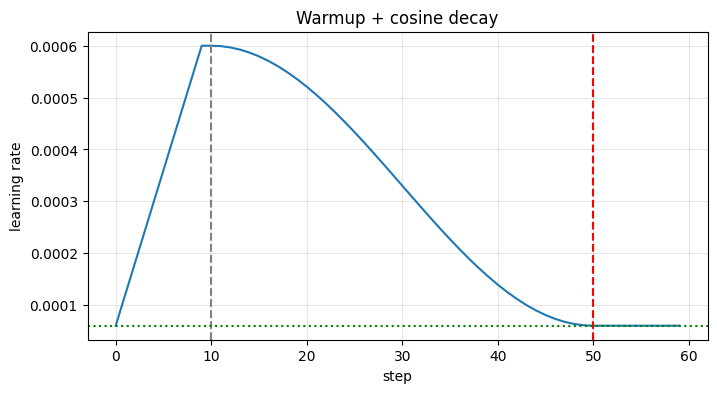

In [66]:
import matplotlib.pyplot as plt

steps = list(range(max_steps + 10))        
lrs = [get_lr(s) for s in steps]

plt.figure(figsize=(8, 4))
plt.plot(steps, lrs)
plt.axvline(warmup_steps, color="gray", linestyle="--")
plt.axvline(max_steps, color="red", linestyle="--")
plt.axhline(min_lr, color="green", linestyle=":")
plt.xlabel("step")
plt.ylabel("learning rate")
plt.title("Warmup + cosine decay")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# configure optimizer fonksiyonunun eklenmesi

class CausalSelfAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        # key, query, value projections for all heads, but in a batch
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        # output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1
        # regularization
        self.n_head = config.n_head
        self.n_embd = config.n_embd

    def forward(self, x):
        B, T, C = x.size() # batch size, sequence length, embedding dimensionality (n_embd)
        # calculate query, key, values for all heads in batch and move head forward to be the batch dim
        # nh is "number of heads", hs is "head size", and C (number of channels) = nh * hs
        # e.g. in GPT-2 (124M), n_head=12, hs=64, so nh*hs=C=768 channels in the Transformer
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True) # flash attention
        y = y.transpose(1, 2).contiguous().view(B, T, C) # re-assemble all head outputs side by side
        # output projection
        y = self.c_proj(y)
        return y

class MLP(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.c_fc    = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu    = nn.GELU(approximate='tanh')
        self.c_proj  = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x

class Block(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024 # max sequence length
    vocab_size: int = 50257 # number of tokens: 50,000 BPE merges + 256 bytes tokens + 1 <|endoftext|> token
    n_layer: int = 12 # number of layers
    n_head: int = 12 # number of heads
    n_embd: int = 768 # embedding dimension

class GPT(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.config = config

        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight

        # init params
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, 'NANOGPT_SCALE_INIT'):
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        # idx is of shape (B, T)
        B, T = idx.size()
        assert T <= self.config.block_size, f"Cannot forward sequence of length {T}, block size is only {self.config.block_size}"
        # forward the token and posisition embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device) # shape (T)
        pos_emb = self.transformer.wpe(pos) # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx) # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layernorm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x) # (B, T, vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @classmethod
    def from_pretrained(cls, model_type):
        """Loads pretrained GPT-2 model weights from huggingface"""
        assert model_type in {'gpt2', 'gpt2-medium', 'gpt2-large', 'gpt2-xl'}
        from transformers import GPT2LMHeadModel
        print("loading weights from pretrained gpt: %s" % model_type)

        # n_layer, n_head and n_embd are determined from model_type
        config_args = {
            'gpt2':         dict(n_layer=12, n_head=12, n_embd=768),  # 124M params
            'gpt2-medium':  dict(n_layer=24, n_head=16, n_embd=1024), # 350M params
            'gpt2-large':   dict(n_layer=36, n_head=20, n_embd=1280), # 774M params
            'gpt2-xl':      dict(n_layer=48, n_head=25, n_embd=1600), # 1558M params
        }[model_type]
        config_args['vocab_size'] = 50257 # always 50257 for GPT model checkpoints
        config_args['block_size'] = 1024 # always 1024 for GPT model checkpoints
        # create a from-scratch initialized minGPT model
        config = GPTConfig(**config_args)
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')] # discard this mask / buffer, not a param

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the parameters are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')] # ignore these, just a buffer
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')] # same, just the mask (buffer)
        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
        # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
            if any(k.endswith(w) for w in transposed):
                # special treatment for the Conv1D weights we need to transpose
                assert sd_hf[k].shape[::-1] == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k].t())
            else:
                # vanilla copy over the other parameters
                assert sd_hf[k].shape == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k])

        return model

    def configure_optimizers(self, weight_decay, learning_rate, device_type):
        # start with all of the candidate parameters (that require grad)
        param_dict = {pn: p for pn, p in self.named_parameters()}
        param_dict = {pn: p for pn, p in param_dict.items() if p.requires_grad}
        # create optim groups. Any parameters that is 2D will be weight decayed, otherwise no.
        # i.e. all weight tensors in matmuls + embeddings decay, all biases and layernorms don't.
        decay_params = [p for n, p in param_dict.items() if p.dim() >= 2]
        nodecay_params = [p for n, p in param_dict.items() if p.dim() < 2]
        optim_groups = [
            {'params': decay_params, 'weight_decay': weight_decay},
            {'params': nodecay_params, 'weight_decay': 0.0}
        ]
        num_decay_params = sum(p.numel() for p in decay_params)
        num_nodecay_params = sum(p.numel() for p in nodecay_params)
        print(f"num decayed parameter tensors: {len(decay_params)}, with {num_decay_params:,} parameters")
        print(f"num non-decayed parameter tensors: {len(nodecay_params)}, with {num_nodecay_params:,} parameters")
        # Create AdamW optimizer and use the fused version if it is available
        fused_available = 'fused' in inspect.signature(torch.optim.AdamW).parameters
        use_fused = fused_available and device_type == "cuda"
        print(f"using fused AdamW: {use_fused}")
        optimizer = torch.optim.AdamW(optim_groups, lr=learning_rate, betas=(0.9, 0.95), eps=1e-8, fused=use_fused)
        return optimizer


Kullanılan cihaz: cuda


In [ ]:
# weight decay
import time
import tiktoken

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B = 4, T = 1024)


# get logits

model = GPT(GPTConfig(vocab_size=50304))
model.to(device)
model = torch.compile(model)

max_lr = 6e-4
min_lr = max_lr * 0.1
warmup_steps = 10
max_steps = 50

def get_lr(it):
    # 1) linear warmup for warmup_iters steps
    if it < warmup_steps:
        return max_lr * (it+1) / warmup_steps
    # 2) if it > lr_decay_iters, return min learning rate
    if it > max_steps:
        return min_lr
    # 3)in between, use cosine decay down to min learning rate

    decay_ratio = (it - warmup_steps) / (max_steps - warmup_steps)
    assert 0 <= decay_ratio <= 1
    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio)) # coeff starts at 1 and goes to 0
    return min_lr + coeff * (max_lr - min_lr)



# optimize

# optimizer = torch.optim.AdamW(model.parameters(), lr = 3e-4, betas = (0.9, 0.95), eps = 1e-8)
optimizer = model.configure_optimizers(weight_decay = 0.1, learning_rate = 6e-4, device_type = device)
for step in range(max_steps):
    t0 = time.time()
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    norm  = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    # determine and set the learning rate for this iteration
    lr = get_lr(step)
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr
    optimizer.step()
    torch.cuda.synchronize()
    t1 = time.time() 
    dt = (t1 - t0) * 1000 # time difference in miliseconds
    tokens_per_sec = (train_loader.B * train_loader.T) / (t1 - t0)
    print(f"step {step}, loss: {loss.item()}, lr: {lr:.4f}, norm: {norm:.4f},  dt: {dt:.2f}ms, tok/sec: {tokens_per_sec:.2f}")
    

loaded 338025 tokens
1 epoch = 82 batches
num decayed parameter tensors: 50, with 124,354,560 parameters
num non-decayed parameter tensors: 98, with 121,344 parameters
using fused AdamW: True
step 0, loss: 10.928756713867188, lr: 0.0001, norm: 30.4259,  dt: 2411.19ms, tok/sec: 1698.74
step 1, loss: 9.615823745727539, lr: 0.0001, norm: 10.5642,  dt: 1191.79ms, tok/sec: 3436.84
step 2, loss: 9.303373336791992, lr: 0.0002, norm: 8.0503,  dt: 1210.58ms, tok/sec: 3383.51
step 3, loss: 9.684585571289062, lr: 0.0002, norm: 6.8213,  dt: 1221.06ms, tok/sec: 3354.46
step 4, loss: 9.003212928771973, lr: 0.0003, norm: 4.5167,  dt: 1234.06ms, tok/sec: 3319.13
step 5, loss: 8.378070831298828, lr: 0.0004, norm: 4.0632,  dt: 1781.36ms, tok/sec: 2299.37
step 6, loss: 8.21664810180664, lr: 0.0004, norm: 2.6391,  dt: 2077.32ms, tok/sec: 1971.77
step 7, loss: 7.931408882141113, lr: 0.0005, norm: 2.7558,  dt: 2263.31ms, tok/sec: 1809.74
step 8, loss: 7.716385841369629, lr: 0.0005, norm: 1.9219,  dt: 1935.8

In [ ]:
# decay parametre 124,354,560
# non decay parametre 121,344 

In [ ]:
import time
import tiktoken

torch.manual_seed(1337)
if torch.cuda.is_available():
    torch.cuda.manual_seed(1337)


total_batch_size = 524288 # 2**19, ~0.5M, in number of tokens
B = 4 # micro batch size
T = 1024 # sequence length
assert total_batch_size % (B * T) == 0,  "make sure total_batch_size is divisible by B * T"
grad_accum_steps = total_batch_size //(B * T)
print(f"total desired batch size: {total_batch_size}")
print(f"=> calculated gradient accumulation steps: {grad_accum_steps} ")


train_loader = DataLoaderLite(B = B, T = T)


# get logits

model = GPT(GPTConfig(vocab_size=50304))
model.to(device)
model = torch.compile(model)

max_lr = 6e-4
min_lr = max_lr * 0.1
warmup_steps = 10
max_steps = 50

def get_lr(it):
    # 1) linear warmup for warmup_iters steps
    if it < warmup_steps:
        return max_lr * (it+1) / warmup_steps
    # 2) if it > lr_decay_iters, return min learning rate
    if it > max_steps:
        return min_lr
    # 3)in between, use cosine decay down to min learning rate

    decay_ratio = (it - warmup_steps) / (max_steps - warmup_steps)
    assert 0 <= decay_ratio <= 1
    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio)) # coeff starts at 1 and goes to 0
    return min_lr + coeff * (max_lr - min_lr)



# optimize

# optimizer = torch.optim.AdamW(model.parameters(), lr = 3e-4, betas = (0.9, 0.95), eps = 1e-8)
optimizer = model.configure_optimizers(weight_decay = 0.1, learning_rate = 6e-4, device_type = device)
for step in range(max_steps):
    t0 = time.time()
    optimizer.zero_grad()
    loss_accum = 0.0
    for micro_step in range(grad_accum_steps):
        x, y = train_loader.next_batch()
        x, y = x.to(device), y.to(device)
        logits, loss = model(x, y)
        loss = loss / grad_accum_steps # normalizer
        # we have to scale the loss to account for gradient accumulation,
        # because the gradients just add on each successive backward().
        # addition of gradients corresponds to a SUM in the objective, but
        # instead of a SUM we want MEAN. Scale the loss here so it comes out right
        loss_accum += loss.detach()
        loss.backward()
    norm  = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    # determine and set the learning rate for this iteration
    lr = get_lr(step)
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr
    optimizer.step()
    torch.cuda.synchronize()
    t1 = time.time() 
    dt = (t1 - t0) * 1000 # time difference in miliseconds
    tokens_per_sec = (train_loader.B * train_loader.T * grad_accum_steps) / (t1 - t0)
    print(f"step {step}, loss: {loss_accum.item()}, lr: {lr:.4f}, norm: {norm:.4f},  dt: {dt:.2f}ms, tok/sec: {tokens_per_sec:.2f}")
    

total desired batch size: 524288
=> calculated gradient accumulation steps: 128 
loaded 338025 tokens
1 epoch = 82 batches
num decayed parameter tensors: 50, with 124,354,560 parameters
num non-decayed parameter tensors: 98, with 121,344 parameters
using fused AdamW: True
step 0, loss: 10.939057350158691, lr: 0.0001, norm: 27.0338,  dt: 128099.05ms, tok/sec: 4092.83
step 1, loss: 9.647130966186523, lr: 0.0001, norm: 9.4959,  dt: 133698.69ms, tok/sec: 3921.41
step 2, loss: 9.225685119628906, lr: 0.0002, norm: 5.7049,  dt: 140147.33ms, tok/sec: 3740.98
step 3, loss: 9.812447547912598, lr: 0.0002, norm: 8.3178,  dt: 139705.71ms, tok/sec: 3752.80
step 4, loss: 9.203254699707031, lr: 0.0003, norm: 4.2671,  dt: 139620.68ms, tok/sec: 3755.09
step 5, loss: 8.6703462600708, lr: 0.0004, norm: 3.6444,  dt: 139663.25ms, tok/sec: 3753.94
step 6, loss: 8.31104850769043, lr: 0.0004, norm: 1.9521,  dt: 139313.98ms, tok/sec: 3763.36
step 7, loss: 8.055402755737305, lr: 0.0005, norm: 2.7233,  dt: 139191

: 

In [ ]:
# lossu neden accumulation grada böldük ? 
# Hedefimiz 524288 token'lık büyük bir batchi tek adımda güncellemek normalde optimizer.step() her backwardtan ağırlıkların güncellediği yer ama biz tek tek bunu yaparsak gpu yetmez zaten 
# çünkü gpu'ya aynı anda yalnızca B*T = 4096 token sığıyor B = 4 sınırında olduğu için çözüm olarak 128 küçük batchi  sırayla işleyip gradient'lerini biriktirmek, sonra tek bir optimizer.step() atmak. 
# normalde biz loss hesaplarken cross_entropy ile her batch içinde ortalam alıyor. 
# Diyelim ki 4 örneğimiz var 1 , 3, 5 , 7 sayıları olsun normalde bunu tek seferde batche girdiğini düşünelim 7 + 5 + 3 + 1  = 16 / 4 = 4 olurdu
# Ancak biz 128 tane batch oluştrduğumuz için tek seferde girmiyor batche yani bunu parçalara ayırıyoruz diyelim ki 7 5 ve 3 1 ayrı ayrı girsin 
# 7 + 5  = 12 / 2 = 6 ve 3 + 1 = 4 / 2 den 2 olurdu bunların toplamı ise 8 olurdu ancak bizim aradığımız sayı 4 . Bu yüzden bunları grad accumulatior sayısına bölüyoruz ki aynı gradlar olsun. 

In [ ]:
# çok fazla uzun süreceği için eğitimi yarıda kestim. O yüzden failed the restart kernel hatasını bilerek bıraktığımı belirtmek isterim.